# Phase 1: Random deposition (1D)

Atoms fall onto a row of 200 columns. Each one lands in a random column and stays where it lands. **Roughness** W is the standard deviation of the column heights.

The model has an exact solution, W(t) = sqrt(t (1 - 1/N)) with t in monolayers, so on a log-log plot W against t is a straight line with slope **beta = 1/2**. Checking that the simulation reproduces this tests the code before we add any real physics.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np
import matplotlib.pyplot as plt
from thin_film import random_deposition as rd
from thin_film.roughness import roughness, fit_growth_exponent
from thin_film.plotting import plot_roughness_loglog, plot_surface

## 1. One film, atom by atom
This uses `deposit_one`, the model's rule written out directly: pick a column and add 1 to it.

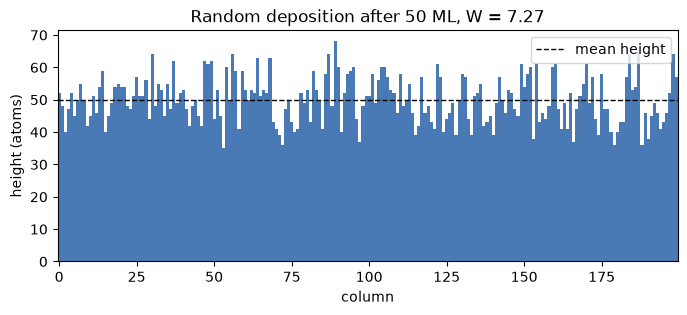

In [2]:
rng = np.random.default_rng(42)
heights = np.zeros(200, dtype=np.int64)
for _ in range(200 * 50):          # 50 monolayers
    rd.deposit_one(heights, rng)
plot_surface(heights, title=f"Random deposition after 50 ML, W = {roughness(heights):.2f}")
plt.show()

The columns are uncorrelated: a tall column has no effect on its neighbours. That is why the surface looks like noise and not like hills and valleys.

## 2. Ensemble average and growth exponent

In [3]:
settings = rd.RDSettings(n_columns=200, n_monolayers=1000, n_runs=30, seed=42)
df = rd.run_ensemble(settings)
beta, err = fit_growth_exponent(df["monolayers"], df["roughness_mean"])
print(f"beta = {beta:.4f} +/- {err:.4f}   (theory: 0.5)")
df.head()

beta = 0.5029 +/- 0.0005   (theory: 0.5)


,atoms,monolayers,roughness_mean,roughness_sem,roughness_theory
0,200,1.000,0.985910,0.009554,0.997497
1,239,1.195,1.080136,0.011165,1.090424
2,285,1.425,1.174288,0.012349,1.190746
3,340,1.700,1.284410,0.013074,1.300577
4,406,2.030,1.404464,0.013871,1.421214


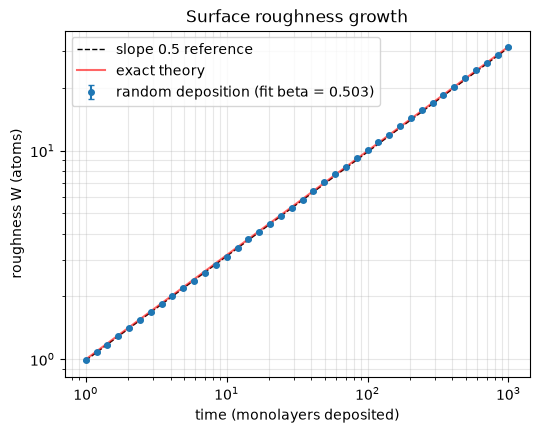

In [4]:
ax = plot_roughness_loglog({"random deposition": df}, {"random deposition": beta})
ax.plot(df["monolayers"], df["roughness_theory"], "r-", alpha=0.6, label="exact theory")
ax.legend(); plt.show()

## 3. One run vs the average
A single film's curve is noisy. Averaging 30 independent films (each with its own seeded random stream) gives the smooth expected curve.

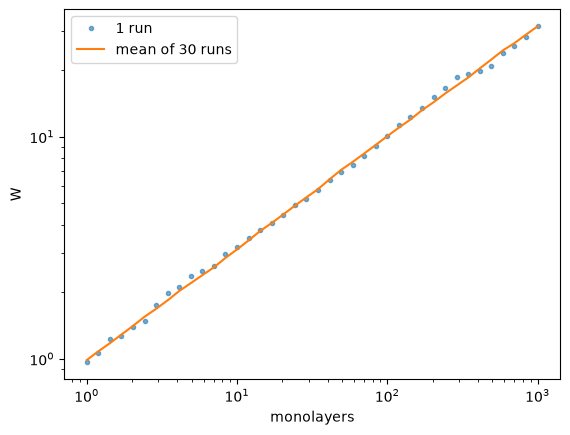

In [5]:
times = rd.measurement_times(200, 1000, 40)
single = rd.simulate(200, times, np.random.default_rng(1))
plt.loglog(times / 200, single, ".", alpha=0.6, label="1 run")
plt.loglog(df["monolayers"], df["roughness_mean"], "-", label="mean of 30 runs")
plt.xlabel("monolayers"); plt.ylabel("W"); plt.legend(); plt.show()

## Takeaways
- W grows as t^(1/2) and never levels off, because the columns are independent and nothing pulls neighbouring heights together.
- Real films stop getting rougher after a while, because atoms move sideways after they land. Phase 2 adds that surface relaxation.